# Exploratory data analysis: where should the robotaxis wait?



The goal is to understand the demand data before we build a forecast or a fleet simulator. We look at the data quality first, then at how demand changes over time and across zones, then at rain and holidays.

Each finding is written in three short lines: what we **observe**, what we **infer** from it, and what it means for the **decision** (D1 launch area, D2 how many cars wait in each zone each hour, D3 should a free car stay or drive empty to a busier zone).

All results are associations. They do not prove a cause.

## 1. The question and the data

A robotaxi has no driver, so the company decides where every car waits. An idle hour or an empty mile costs money. We use the 2024 Uber and Lyft trips in New York as a stand-in for robotaxi demand.

Table used: `zone_hour`, built in Phase 1. One row is one taxi zone in one hour (263 zones). It holds request counts, pickups, drop-offs, trip miles and minutes, base fares, weather and the holiday flag.

We only read **January to October 2024**. November and December are the final test and January 2025 is the drift check, so we keep them out of the EDA.

In [1]:
import json
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.dataset as ds
import seaborn as sns
from IPython.display import Markdown, display
from scipy import stats

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "repo_instructions.md").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Run this from the repository folder.")

sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.2f}".format

In [2]:
RELEASE = ROOT / "data/releases/phase1-2024-v1"
OUTPUT = ROOT / "data/eda/phase2_simple"
OUTPUT.mkdir(parents=True, exist_ok=True)

PERIODS = ["train", "validation"]    # January to October 2024
LAST_DAY_ALLOWED = "2024-10-31"
SEED = 240514
COST_PER_MILE = 1.36
PRACTICAL_GAP = 0.10
OUTLIER_CUTOFF = 3.5
HOLIDAY_WINDOW_DAYS = 28
FLEET_SIZES = [25, 50, 100]
DEMAND_SCALE = 0.01
BASELINE_START = "2024-04-01"
WEEKDAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

### Settings: what, why, and when we fixed them

| Setting | Value | What it is and why | Fixed |
|---|---|---|---|
| Data window | Jan to Oct 2024 | We choose forecast settings with seven monthly walk-forward folds inside January to October (`docs/decisions.md`, 2026-11-16). So the EDA stays inside the same months. Reading November, December or January 2025 here could leak into choices that are later judged on those months. The code stops with an error if a later date appears. | Before results |
| Seed | 240514 | Makes every random draw repeat. The value itself does not matter. | Before results |
| Cost per mile | 1.36 USD | Cost of every mile driven, empty ones included. It comes from the plan. | Before results |
| Outlier cut-off | 3.5 | The usual cut-off for a median-based z-score. | Before results |
| History lags | 1 to 4 weeks | Same zone, weekday and hour in the four earlier weeks. These are the inputs of the Phase 3b forecast. | Before results |
| Baseline months | April to October | January to March are needed as history. April to October are the months the seven walk-forward folds validate. | Before results |
| Holiday window | 28 days | A holiday is compared with normal days of the same weekday, at most four weeks away. | Before results |
| Fleet sizes and demand scale | 25, 50, 100 cars and 1% of demand | Same as the fleet simulator, so the quick check in Section 15 matches it. | Before results |
| Small boroughs | boroughs with under 1% of demand are left out of the error table in Section 14 | Newark (borough EWR) is one zone with almost no demand, and its error percentage is meaningless (about 190%). | After seeing the data |
| Rain rule | wet: station reports rain. dry: no weather event reported and precipitation exactly 0 | We found while building this notebook that the rain flag is empty when the station reports no weather event at all, so an empty flag cannot be read as "unknown". Hours with mist, haze or snow are left out of the wet and dry groups. | After seeing the data |

In [1]:
FINDINGS = []


def show_finding(topic, observation, inference, decision):
    """Print one finding in three lines and keep it for the table at the end."""
    FINDINGS.append({"Topic": topic, "Observation": observation,
                     "Inference": inference, "Decision relevance": decision})
    text = f"**{topic}**\n\n"
    text += f"- Observation: {observation}\n"
    text += f"- Inference: {inference}\n"
    text += f"- Decision relevance: {decision}"
    display(Markdown(text))

## 2. Load the data and check it

We read only the columns we need and only the periods `train` and `validation` (January to October). Then we check three things: no date after October, each zone-hour appears once, and request counts are never negative.

A request count that is empty means the hour was not fully covered. We never turn it into zero.

In [2]:
table_index = json.loads((RELEASE / "metadata/table_index.json").read_text())
zone_hour = ds.dataset(ROOT / table_index["zone_hour"]["path"],
                       format="parquet", partitioning="hive")

columns = [
    "zone_id", "zone_name", "borough", "is_airport",
    "hour_start_utc", "event_date_nyc", "hour_nyc", "period_label",
    "request_count", "pickup_count", "dropoff_count",
    "pickup_coverage_complete", "dropoff_coverage_complete",
    "passenger_miles_sum", "passenger_minutes_sum", "passenger_measure_count",
    "valid_base_fare_sum_usd", "valid_fare_count",
    "has_observed_rain", "precipitation_previous_hour_mm",
    "has_observed_rain_laguardia", "precipitation_previous_hour_mm_laguardia",
    "has_observed_rain_jfk", "precipitation_previous_hour_mm_jfk",
    "is_federal_holiday", "holiday_name"]

hours = zone_hour.to_table(
    columns=columns,
    filter=ds.field("period_label").isin(PERIODS)).to_pandas()

NameError: name 'json' is not defined

In [ ]:
hours["hour_start_utc"] = pd.to_datetime(hours["hour_start_utc"], utc=True)
hours["event_date_nyc"] = pd.to_datetime(hours["event_date_nyc"])
hours["month"] = hours["event_date_nyc"].dt.month
hours["weekday"] = hours["event_date_nyc"].dt.day_of_week

local_time = hours["hour_start_utc"].dt.tz_convert("America/New_York")
hours["civil_hour"] = local_time.dt.tz_localize(None)

rain_flags = ["has_observed_rain", "has_observed_rain_laguardia",
              "has_observed_rain_jfk", "is_federal_holiday"]
for flag in rain_flags:
    hours[flag] = hours[flag].astype(float)

In [ ]:
assert hours["event_date_nyc"].max() <= pd.Timestamp(LAST_DAY_ALLOWED)
assert not hours.duplicated(["zone_id", "hour_start_utc"]).any()
assert (hours["request_count"].dropna() >= 0).all()

print("Rows:", f"{len(hours):,}")
print("Real hours:", f"{hours['hour_start_utc'].nunique():,}")
print("Zones:", hours["zone_id"].nunique())
print("Dates:", hours["event_date_nyc"].min().date(), "to",
      hours["event_date_nyc"].max().date())

Rows: 1,924,897
Real hours: 7,319
Zones: 263
Dates: 2024-01-01 to 2024-10-31


In [ ]:
run_summary = json.loads((RELEASE / "metadata/run_summary.json").read_text())
counts = run_summary["validated_cleaning_source_counts"]["analysis"]

data_card = pd.Series({
    "Rows in the full zone_hour table": f"{table_index['zone_hour']['rows']:,}",
    "Rows used here (Jan to Oct 2024)": f"{len(hours):,}",
    "Columns in the table": len(zone_hour.schema.names),
    "Trip records in the Phase 1 cleaning run": f"{counts['input_rows']:,}",
    "Sources": "NYC TLC trips (Uber, Lyft), TLC zones, NOAA weather, US holidays"})
display(data_card.to_frame("value"))

,value
Rows in the full zone_hour table,"2,505,864"
Rows used here (Jan to Oct 2024),"1,924,897"
Columns in the table,151
Trip records in the Phase 1 cleaning run,"259,876,114"
Sources,"NYC TLC trips (Uber, Lyft), TLC zones, NOAA we..."


## 3. Data quality

Three questions. How much is empty? How many trips did the cleaning rules remove? Are the two providers treated the same?

The cleaning counts below come from the Phase 1 run summary, which covers the whole run (all of 2024 and January 2025). They are counts of removed trips, not demand, and nothing is chosen from them. The provider table is limited to January to October.

An empty `request_count` means not fully covered. `has_observed_rain` is empty when the weather station reported no weather event, so it is not a real missing value (see the rain rule above).

In [8]:
check = ["request_count", "pickup_count", "dropoff_count",
         "valid_base_fare_sum_usd", "precipitation_previous_hour_mm"]
missing_percent = hours[check].isna().mean() * 100
display(missing_percent.round(2).to_frame("% empty"))

covered = hours[hours["request_count"].notna()]
zero_percent = (covered["request_count"] == 0).mean() * 100
print(f"Covered zone-hours with zero requests: {zero_percent:.1f}%")

,% empty
request_count,0.00
pickup_count,0.07
dropoff_count,0.00
valid_base_fare_sum_usd,0.00
precipitation_previous_hour_mm,6.12


Covered zone-hours with zero requests: 4.3%


In [9]:
rule_names = {
    "has_invalid_request_order": "request not before pickup",
    "has_duration_outside_limits": "duration outside 1 minute to 3 hours",
    "has_speed_outside_limits": "speed outside 1 to 80 mph",
    "has_invalid_dropoff_order": "drop-off not after pickup",
    "is_negative_base_fare_usd": "negative base fare",
    "has_repeated_key": "same key as another record (flagged, not removed)"}

rules = pd.DataFrame({"records hit": {name: counts[key] for key, name in rule_names.items()}})
rules["% of input"] = 100 * rules["records hit"] / counts["input_rows"]
display(rules.sort_values("records hit", ascending=False))

input_rows = counts["input_rows"]
accepted = counts["is_accepted"]
print(f"{input_rows:,} records in, {accepted:,} kept ({100 * accepted / input_rows:.2f}%)")

,records hit,% of input
request not before pickup,2518592,0.97
speed outside 1 to 80 mph,80463,0.03
duration outside 1 minute to 3 hours,29842,0.01
negative base fare,20660,0.01
drop-off not after pickup,9684,0.00
"same key as another record (flagged, not removed)",16,0.00


259,876,114 records in, 257,260,513 kept (98.99%)


In [10]:
provider_data = ds.dataset(ROOT / table_index["provider_exclusions"]["path"], format="parquet")
in_window = (
    (ds.field("recorded_civil_hour") >= pa.scalar(datetime(2024, 1, 1)))
    & (ds.field("recorded_civil_hour") < pa.scalar(datetime(2024, 11, 1)))
    & (ds.field("time_basis") == "recorded_pickup_hour"))

provider = provider_data.to_table(
    columns=["service_license", "input_count", "sequential_request_order_exclusions"],
    filter=in_window).to_pandas()
provider = provider.groupby("service_license").sum()
provider["% removed"] = 100 * provider["sequential_request_order_exclusions"] / provider["input_count"]
provider.index = provider.index.map({"HV0003": "Uber", "HV0005": "Lyft"})
display(provider)

,input_count,sequential_request_order_exclusions,% removed
service_license,,,
Uber,148067368,1005067,0.68
Lyft,50346696,851755,1.69


In [11]:
lyft_percent = provider.loc["Lyft", "% removed"]
uber_percent = provider.loc["Uber", "% removed"]

show_finding(
    "Data quality: little is lost, but not evenly",
    (f"{100 * accepted / input_rows:.2f}% of the trip records pass cleaning. "
     f"The rule 'request not before pickup' removes {lyft_percent:.2f}% of Lyft trips "
     f"and {uber_percent:.2f}% of Uber trips. "
     f"{int(hours['request_count'].isna().sum())} zone-hours have no request count."),
    ("The demand count is almost complete, but it is a count of eligible completed trips, "
     "not of all requests. Lyft loses more trips than Uber, so the count may lean slightly "
     "towards Uber. We cannot tell how large that bias is."),
    ("Call the demand 'eligible completed trips' everywhere and keep missing hours missing, "
     "never zero. Mention this limit when we present the launch area (D1)."))

**Data quality: little is lost, but not evenly**

- Observation: 98.99% of the trip records pass cleaning. The rule 'request not before pickup' removes 1.69% of Lyft trips and 0.68% of Uber trips. 0 zone-hours have no request count.
- Inference: The demand count is almost complete, but it is a count of eligible completed trips, not of all requests. Lyft loses more trips than Uber, so the count may lean slightly towards Uber. We cannot tell how large that bias is.
- Decision relevance: Call the demand 'eligible completed trips' everywhere and keep missing hours missing, never zero. Mention this limit when we present the launch area (D1).

## 4. One row per hour for the whole city

Several questions below are about the city as a whole (time patterns, rain, holidays), so we add up the zones for each hour. If even one zone is not covered in an hour, we leave that hour's total empty.

The weather and the holiday flag are the same in every zone, so we just take the first value.

In [12]:
by_hour = hours.groupby("hour_start_utc")
city = by_hour.agg(requests=("request_count", "sum"),
                   zones_covered=("request_count", "count"))

same_for_all_zones = [
    "event_date_nyc", "month", "weekday", "hour_nyc",
    "is_federal_holiday", "holiday_name",
    "has_observed_rain", "precipitation_previous_hour_mm",
    "has_observed_rain_laguardia", "precipitation_previous_hour_mm_laguardia",
    "has_observed_rain_jfk", "precipitation_previous_hour_mm_jfk"]
city = city.join(by_hour[same_for_all_zones].first())

city.loc[city["zones_covered"] < 263, "requests"] = np.nan
city["is_rain"] = city["has_observed_rain"] == 1
print(len(city), "hours,", city["requests"].isna().sum(), "without a full city total")

7319 hours, 0 without a full city total


## 5. Summary statistics and the shape of demand

First the plain numbers for the request count of one zone in one hour: mean, median, spread and the biggest value. Then a histogram.

We also check how noisy the counts are. For a pure random (Poisson) count the variance equals the mean. We compute variance divided by mean for each zone, weekday and hour. A value well above 1 means the counts swing more than pure chance.

In [13]:
display(covered["request_count"].describe().to_frame("requests per zone-hour"))

skew = covered["request_count"].skew()
print(f"Skew: {skew:.1f} (0 would be symmetric)")

,requests per zone-hour
count,"1,924,897.00"
mean,102.07
std,116.70
min,0.00
25%,24.00
50%,67.00
75%,142.00
max,"1,691.00"


Skew: 2.8 (0 would be symmetric)


In [14]:
cell = covered.groupby(["zone_id", "weekday", "hour_nyc"])["request_count"]
cell_stats = cell.agg(["mean", "var", "count"])
cell_stats = cell_stats[(cell_stats["count"] >= 20) & (cell_stats["mean"] > 0)]
cell_stats["variance_over_mean"] = cell_stats["var"] / cell_stats["mean"]

median_ratio = cell_stats["variance_over_mean"].median()
share_above_one = (cell_stats["variance_over_mean"] > 1).mean() * 100
print(f"Median variance / mean: {median_ratio:.1f}")
print(f"{share_above_one:.0f}% of the {len(cell_stats):,} cells have variance above the mean")

Median variance / mean: 2.1
90% of the 43,346 cells have variance above the mean


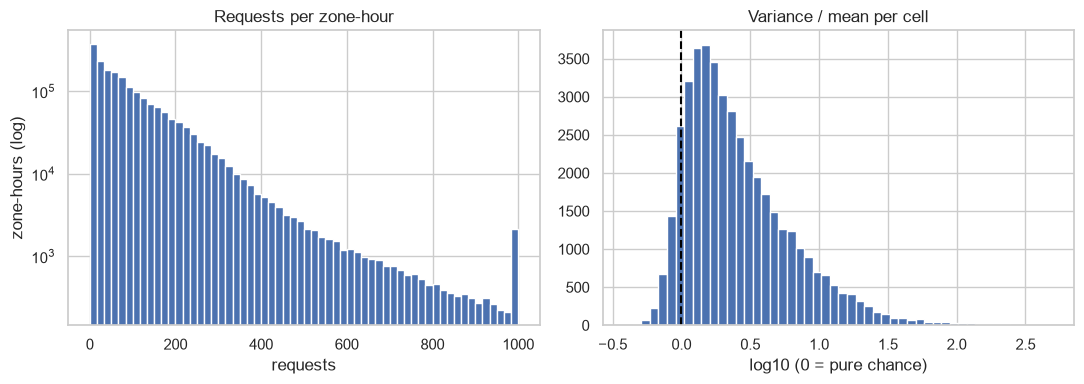

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

top_value = covered["request_count"].quantile(0.999)
axes[0].hist(covered["request_count"].clip(upper=top_value), bins=60)
axes[0].set_yscale("log")
axes[0].set(title="Requests per zone-hour", xlabel="requests", ylabel="zone-hours (log)")

axes[1].hist(np.log10(cell_stats["variance_over_mean"]), bins=50)
axes[1].axvline(0, color="black", linestyle="--")
axes[1].set(title="Variance / mean per cell", xlabel="log10 (0 = pure chance)")
plt.tight_layout()
plt.show()

In [16]:
zone_average = covered.groupby("zone_id")["request_count"].mean()
quiet_zones = zone_average[zone_average <= zone_average.quantile(0.25)].index
quiet_zero_percent = (covered[covered["zone_id"].isin(quiet_zones)]["request_count"] == 0).mean() * 100

show_finding(
    "Shape of demand: lopsided and noisy",
    (f"The mean is {covered['request_count'].mean():.1f} requests per zone-hour but the median is "
     f"{covered['request_count'].median():.0f} and the maximum is {covered['request_count'].max():,.0f} "
     f"(skew {skew:.1f}). Variance is about {median_ratio:.1f} times the mean. "
     f"In the quietest quarter of zones, {quiet_zero_percent:.0f}% of zone-hours have no request."),
    ("A few very busy zone-hours pull the mean up, and the counts swing more than pure chance. "
     "Part of that is real change (weather, events) and part is luck in small counts."),
    ("Keep a Poisson-type loss as a candidate for the forecast, and report forecast error as WAPE "
     "(total error divided by total demand) so empty hours do not break it. Do not promise "
     "exact counts for the quietest zones (D2)."))

**Shape of demand: lopsided and noisy**

- Observation: The mean is 102.1 requests per zone-hour but the median is 67 and the maximum is 1,691 (skew 2.8). Variance is about 2.1 times the mean. In the quietest quarter of zones, 17% of zone-hours have no request.
- Inference: A few very busy zone-hours pull the mean up, and the counts swing more than pure chance. Part of that is real change (weather, events) and part is luck in small counts.
- Decision relevance: Keep a Poisson-type loss as a candidate for the forecast, and report forecast error as WAPE (total error divided by total demand) so empty hours do not break it. Do not promise exact counts for the quietest zones (D2).

## 6. Outliers

We look for unusual days. For each day we take the average number of requests per hour in the whole city. We compare each day with other days of the **same weekday**, because a Saturday should not be judged against a Tuesday.

The score is a robust z-score: how far the day is from the median, measured in typical spreads (the median absolute deviation, MAD). A day with a score beyond 3.5 is flagged. We use the median instead of the mean so that outliers do not hide themselves.

In [17]:
daily = city.groupby("event_date_nyc").agg(
    mean_requests=("requests", "mean"),
    hours_counted=("requests", "count"),
    hours_in_day=("requests", "size"),
    weekday=("weekday", "first"),
    is_holiday=("is_federal_holiday", "max"),
    holiday=("holiday_name", "first"),
    rainy_hours=("is_rain", "sum"))
daily = daily[daily["hours_counted"] == daily["hours_in_day"]].copy()

In [18]:
def robust_z(values):
    """How many MAD spreads each value is from the median."""
    median = values.median()
    mad = (values - median).abs().median()
    return 0.6745 * (values - median) / mad


daily["z"] = daily.groupby("weekday")["mean_requests"].transform(robust_z)
flagged = daily[daily["z"].abs() > OUTLIER_CUTOFF]
print(len(daily), "full days checked,", len(flagged), "flagged")
display(flagged[["mean_requests", "z", "holiday", "rainy_hours"]])

305 full days checked, 9 flagged


,mean_requests,z,holiday,rainy_hours
event_date_nyc,,,,
2024-01-01,"26,476.12",3.66,New Year's Day,3
2024-01-02,"19,658.67",-5.04,NaN,0
2024-01-07,"22,415.08",-4.19,NaN,8
2024-02-13,"20,931.25",-3.58,NaN,1
2024-03-05,"27,311.83",3.75,NaN,11
2024-03-09,"36,727.04",3.53,NaN,12
2024-04-02,"28,011.71",4.56,NaN,15
2024-04-03,"31,034.92",3.55,NaN,20
2024-07-06,"25,820.46",-4.07,NaN,0


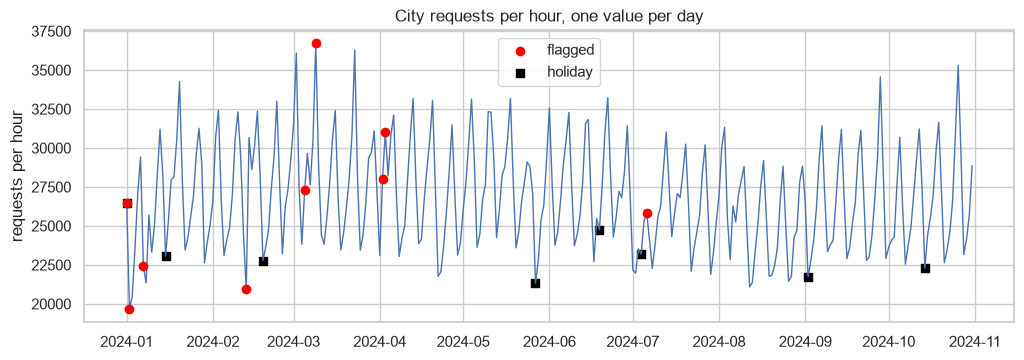

In [19]:
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(daily.index, daily["mean_requests"], linewidth=1)
ax.scatter(flagged.index, flagged["mean_requests"], color="red", zorder=3, label="flagged")
holidays = daily[daily["is_holiday"] == 1]
ax.scatter(holidays.index, holidays["mean_requests"], color="black", marker="s", label="holiday")
ax.set(title="City requests per hour, one value per day", ylabel="requests per hour")
ax.legend()
plt.show()

In [20]:
explained = (flagged["is_holiday"] == 1) | (flagged["rainy_hours"] > 0)

show_finding(
    "Outliers: unusual days are mostly explained",
    (f"{len(flagged)} of {len(daily)} days are flagged. {int(explained.sum())} of them are federal "
     f"holidays or have rainy hours. No count is negative."),
    ("These days are real swings in demand, not data errors. The few without a holiday or rain "
     "probably come from events or transit problems, which we do not have in the data."),
    ("Keep these days in training, because they are exactly where a forecast is hardest. "
     "Report holidays and wet days separately when we evaluate plans."))

**Outliers: unusual days are mostly explained**

- Observation: 9 of 305 days are flagged. 7 of them are federal holidays or have rainy hours. No count is negative.
- Inference: These days are real swings in demand, not data errors. The few without a holiday or rain probably come from events or transit problems, which we do not have in the data.
- Decision relevance: Keep these days in training, because they are exactly where a forecast is hardest. Report holidays and wet days separately when we evaluate plans.

## 7. Demand over time

Two charts. The first shows each month against the January to October average (100 = average). The second shows the average city demand for every weekday and hour.

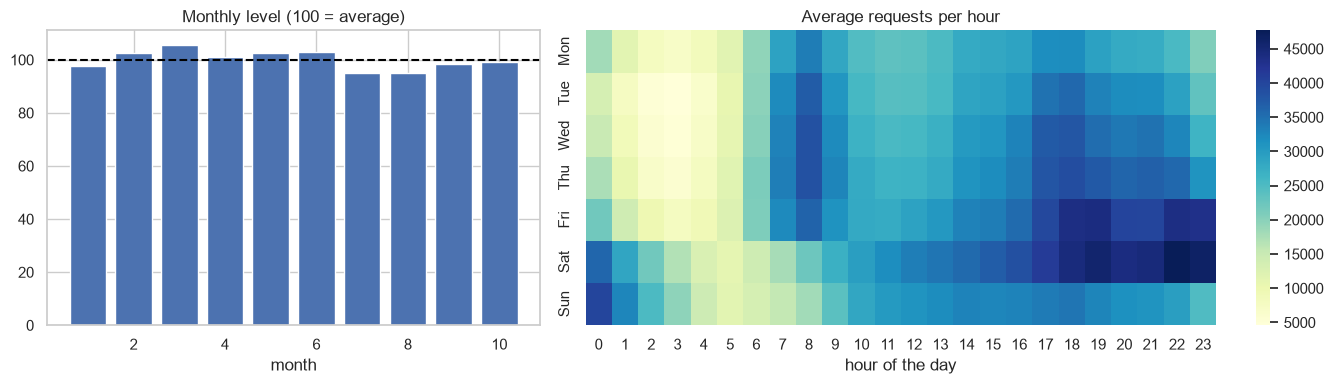

In [21]:
full = city.dropna(subset=["requests"])
month_level = full.groupby("month")["requests"].mean()
month_index = 100 * month_level / full["requests"].mean()

weekday_hour = full.pivot_table(index="weekday", columns="hour_nyc",
                                values="requests", aggfunc="mean")
weekday_hour.index = WEEKDAYS

fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [1, 1.6]})
axes[0].bar(month_index.index, month_index.values)
axes[0].axhline(100, color="black", linestyle="--")
axes[0].set(title="Monthly level (100 = average)", xlabel="month")
sns.heatmap(weekday_hour, cmap="YlGnBu", ax=axes[1])
axes[1].set(title="Average requests per hour", xlabel="hour of the day")
plt.tight_layout()
plt.show()

In [22]:
peak = weekday_hour.stack().idxmax()
peak_value = weekday_hour.stack().max()
night_value = weekday_hour[4].mean()
month_gap = month_index.max() - month_index.min()

show_finding(
    "Demand over time: strong weekly rhythm, small month effect",
    (f"The busiest slot is {peak[0]} at {peak[1]:02d}:00 with {peak_value:,.0f} requests per hour "
     f"for the city. At 04:00 demand is only {100 * night_value / peak_value:.0f}% of that. "
     f"The lowest and highest month are {month_gap:.0f} index points apart."),
    "Weekday and hour explain most of the pattern. The shape repeats every week.",
    ("Plan car positions by weekday and hour, not by month. The evening and weekend-night peaks "
     "are where a small fleet is most likely to run short (D2)."))

**Demand over time: strong weekly rhythm, small month effect**

- Observation: The busiest slot is Sat at 22:00 with 47,683 requests per hour for the city. At 04:00 demand is only 20% of that. The lowest and highest month are 11 index points apart.
- Inference: Weekday and hour explain most of the pattern. The shape repeats every week.
- Decision relevance: Plan car positions by weekday and hour, not by month. The evening and weekend-night peaks are where a small fleet is most likely to run short (D2).

## 8. Demand by zone

We take each zone's average requests per covered hour, rank the zones, and ask how many zones hold half, 80% and 90% of all demand. This matters for the launch area (D1).

In [23]:
zone_table = covered.groupby(["zone_id", "zone_name", "borough"])["request_count"].mean()
zone_table = zone_table.sort_values(ascending=False).reset_index(name="mean_requests")
zone_table["share"] = zone_table["mean_requests"] / zone_table["mean_requests"].sum()
zone_table["% of demand"] = 100 * zone_table["share"]
zone_table["cumulative"] = zone_table["share"].cumsum()

zones_needed = {}
for target in [0.5, 0.8, 0.9]:
    zones_needed[target] = int((zone_table["cumulative"] < target).sum() + 1)
print("Zones needed for 50%, 80%, 90% of demand:", list(zones_needed.values()))

top_ten_share = zone_table["share"].head(10).sum()
print(f"Top 10 zones hold {100 * top_ten_share:.1f}% of demand")
display(zone_table.head(8)[["zone_name", "borough", "mean_requests", "% of demand"]])

Zones needed for 50%, 80%, 90% of demand: [57, 123, 161]
Top 10 zones hold 13.4% of demand


,zone_name,borough,mean_requests,% of demand
0,LaGuardia Airport,Queens,537.65,2.00
1,JFK Airport,Queens,500.47,1.86
2,East Village,Manhattan,358.42,1.34
3,Crown Heights North,Brooklyn,352.58,1.31
4,Times Sq/Theatre District,Manhattan,328.30,1.22
5,Midtown Center,Manhattan,316.13,1.18
6,TriBeCa/Civic Center,Manhattan,306.75,1.14
7,East Chelsea,Manhattan,302.16,1.13


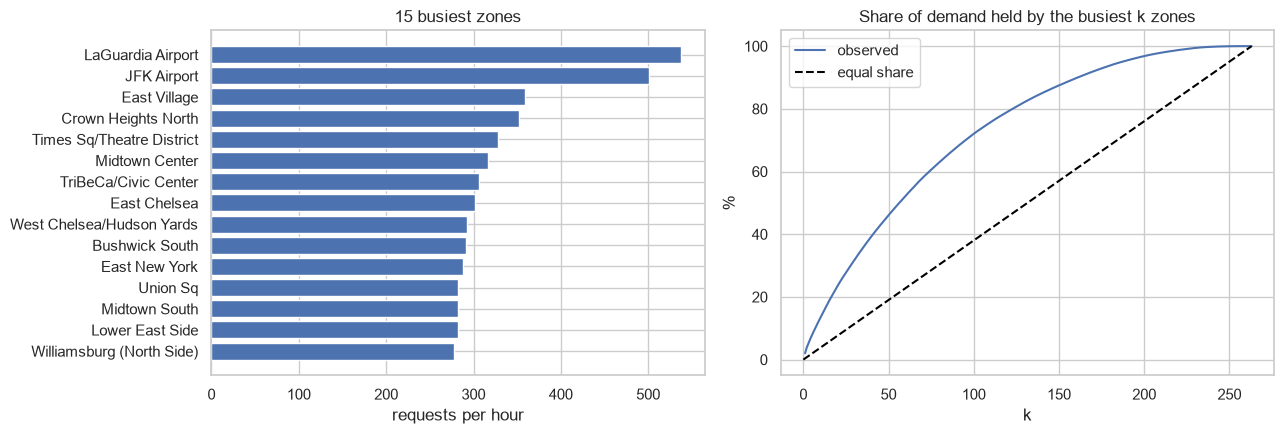

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
top15 = zone_table.head(15).iloc[::-1]
axes[0].barh(top15["zone_name"], top15["mean_requests"])
axes[0].set(title="15 busiest zones", xlabel="requests per hour")

axes[1].plot(range(1, 264), 100 * zone_table["cumulative"], label="observed")
axes[1].plot([0, 263], [0, 100], "--", color="black", label="equal share")
axes[1].set(title="Share of demand held by the busiest k zones", xlabel="k", ylabel="%")
axes[1].legend()
plt.tight_layout()
plt.show()

In [25]:
borough_share = zone_table.groupby("borough")["share"].sum() * 100
zones_per_borough = zone_table.groupby("borough")["zone_id"].count()
borough_table = pd.DataFrame({"% of demand": borough_share, "zones": zones_per_borough})
display(borough_table.sort_values("% of demand", ascending=False))

,% of demand,zones
borough,,
Manhattan,38.93,69
Brooklyn,26.38,61
Queens,20.92,69
Bronx,12.32,43
Staten Island,1.46,20
EWR,0.00,1


In [26]:
manhattan_share = borough_share["Manhattan"]

show_finding(
    "Demand by zone: spread out, but with a clear core",
    (f"{zones_needed[0.5]} zones hold half of the demand, {zones_needed[0.8]} hold 80% and "
     f"{zones_needed[0.9]} hold 90% of 263. The ten busiest zones hold {100 * top_ten_share:.0f}%. "
     f"Manhattan holds {manhattan_share:.0f}% of demand."),
    ("Demand is not concentrated in a handful of zones, so a launch area has to be fairly large "
     "to cover most requests. Outer-borough demand is real but thin."),
    ("Choose the launch area (D1) by comparing profit, not only by demand share, because "
     "thin zones are expensive to serve with few cars."))

**Demand by zone: spread out, but with a clear core**

- Observation: 57 zones hold half of the demand, 123 hold 80% and 161 hold 90% of 263. The ten busiest zones hold 13%. Manhattan holds 39% of demand.
- Inference: Demand is not concentrated in a handful of zones, so a launch area has to be fairly large to cover most requests. Outer-borough demand is real but thin.
- Decision relevance: Choose the launch area (D1) by comparing profit, not only by demand share, because thin zones are expensive to serve with few cars.

## 9. Trip economics

What does an average trip look like, and how much does it leave before empty miles and idle time are paid? For each borough we add up miles, minutes and base fares and divide by the number of trips.

Revenue is the base passenger fare only (tips are left out). "Left after mileage cost" is fare minus 1.36 USD per trip mile. Empty miles and idle time come later in the simulator, so this is an upper limit.

In [27]:
sums = hours.groupby("borough")[["passenger_miles_sum", "passenger_minutes_sum",
                                 "passenger_measure_count", "valid_base_fare_sum_usd",
                                 "valid_fare_count"]].sum()
sums.loc["All zones"] = sums.sum()

economics = pd.DataFrame(index=sums.index)
economics["miles per trip"] = sums["passenger_miles_sum"] / sums["passenger_measure_count"]
economics["minutes per trip"] = sums["passenger_minutes_sum"] / sums["passenger_measure_count"]
economics["base fare (USD)"] = sums["valid_base_fare_sum_usd"] / sums["valid_fare_count"]
economics["left after mileage cost (USD)"] = (
    economics["base fare (USD)"] - COST_PER_MILE * economics["miles per trip"])
display(economics)

,miles per trip,minutes per trip,base fare (USD),left after mileage cost (USD)
borough,,,,
Bronx,4.37,16.77,19.47,13.53
Brooklyn,4.22,19.01,22.13,16.39
EWR,3.16,9.47,67.23,62.93
Manhattan,4.99,20.87,28.96,22.18
Queens,6.52,21.53,28.64,19.77
Staten Island,5.13,15.82,21.21,14.23
All zones,5.03,19.94,25.81,18.97


In [28]:
city_row = economics.loc["All zones"]

show_finding(
    "Trip economics: a trip leaves a modest margin",
    (f"The average trip is {city_row['miles per trip']:.1f} miles and "
     f"{city_row['minutes per trip']:.0f} minutes with a base fare of "
     f"{city_row['base fare (USD)']:.2f} USD. After {COST_PER_MILE} USD per mile "
     f"{city_row['left after mileage cost (USD)']:.2f} USD is left."),
    ("Trips differ by borough. Every empty mile costs the same as a paid mile but earns nothing, "
     "so a few empty miles remove a large part of this margin."),
    ("The wait-or-move rule (D3) has to count the empty-mile cost of every move, "
     "otherwise moving cars always looks good."))

**Trip economics: a trip leaves a modest margin**

- Observation: The average trip is 5.0 miles and 20 minutes with a base fare of 25.81 USD. After 1.36 USD per mile 18.97 USD is left.
- Inference: Trips differ by borough. Every empty mile costs the same as a paid mile but earns nothing, so a few empty miles remove a large part of this margin.
- Decision relevance: The wait-or-move rule (D3) has to count the empty-mile cost of every move, otherwise moving cars always looks good.

## 10. Where trips start and where they end

For each zone we compute pickups minus drop-offs per hour. A positive number means more cars leave than arrive, so the zone needs cars brought in. A negative number means cars pile up there.

We only use hours where both counts are fully covered.

In [29]:
both_covered = (hours["pickup_coverage_complete"].astype(bool)
                & hours["dropoff_coverage_complete"].astype(bool))
flow = hours[both_covered].copy()
flow["net_pickups"] = flow["pickup_count"] - flow["dropoff_count"]

zone_flow = flow.groupby(["zone_id", "zone_name", "borough"])["net_pickups"].mean()
zone_flow = zone_flow.sort_values().reset_index(name="net_per_hour")
display(zone_flow.head(5))
display(zone_flow.tail(5))

,zone_id,zone_name,borough,net_per_hour
0,1,Newark Airport,EWR,-172.52
1,132,JFK Airport,Queens,-53.43
2,186,Penn Station/Madison Sq West,Manhattan,-49.71
3,61,Crown Heights North,Brooklyn,-17.38
4,43,Central Park,Manhattan,-15.60


,zone_id,zone_name,borough,net_per_hour
258,164,Midtown South,Manhattan,40.93
259,48,Clinton East,Manhattan,46.69
260,231,TriBeCa/Civic Center,Manhattan,47.10
261,148,Lower East Side,Manhattan,62.40
262,79,East Village,Manhattan,62.87


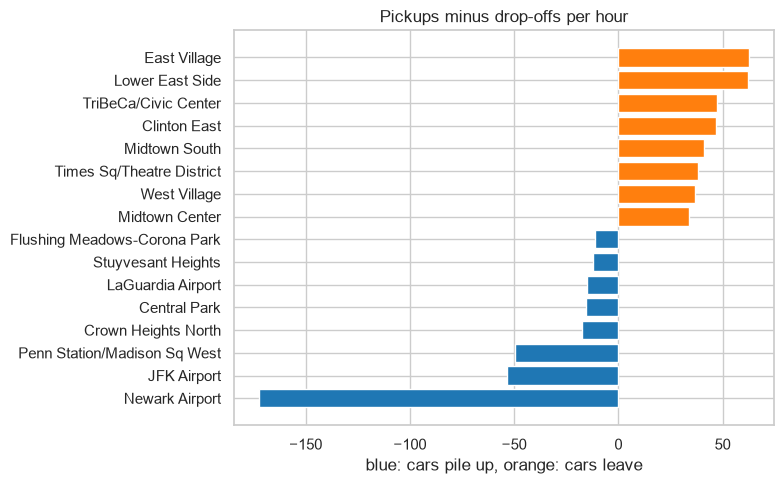

In [30]:
extremes = pd.concat([zone_flow.head(8), zone_flow.tail(8)])
colours = np.where(extremes["net_per_hour"] > 0, "tab:orange", "tab:blue")

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(extremes["zone_name"], extremes["net_per_hour"], color=colours)
ax.set(title="Pickups minus drop-offs per hour", xlabel="blue: cars pile up, orange: cars leave")
plt.tight_layout()
plt.show()

In [31]:
most_cars_leave = zone_flow.iloc[-1]
most_cars_pile_up = zone_flow.iloc[0]

show_finding(
    "Flows: cars drift towards a few zones",
    (f"{most_cars_leave['zone_name']} loses the most cars "
     f"({most_cars_leave['net_per_hour']:+.1f} net pickups per hour). "
     f"{most_cars_pile_up['zone_name']} collects the most "
     f"({most_cars_pile_up['net_per_hour']:+.1f})."),
    ("Airports and end-of-line zones collect cars that must drive back empty. "
     "Zones that lose cars every hour need cars sent in."),
    ("Test 'stay' against 'drive empty to a busier zone' with the empty-mile cost included (D3), "
     "and look first at the zones that lose or collect the most cars."))

**Flows: cars drift towards a few zones**

- Observation: East Village loses the most cars (+62.9 net pickups per hour). Newark Airport collects the most (-172.5).
- Inference: Airports and end-of-line zones collect cars that must drive back empty. Zones that lose cars every hour need cars sent in.
- Decision relevance: Test 'stay' against 'drive empty to a busier zone' with the empty-mile cost included (D3), and look first at the zones that lose or collect the most cars.

## 11. Rain and federal holidays

**Rain.** We compare each rainy hour with the average of dry hours that have the same month, weekday and clock hour, so the normal weekly pattern is removed. We then add up each rainy day and compare actual with expected demand. A paired Wilcoxon test checks whether wet days are higher than expected.

The same is done with the LaGuardia and JFK weather stations as an independent check. If three stations tell the same story, we trust it more.

Wet and dry follow the rain rule in the settings table above.

In [32]:
stations = {
    "Central Park": ("has_observed_rain", "precipitation_previous_hour_mm"),
    "LaGuardia": ("has_observed_rain_laguardia", "precipitation_previous_hour_mm_laguardia"),
    "JFK": ("has_observed_rain_jfk", "precipitation_previous_hour_mm_jfk")}
cell_keys = ["month", "weekday", "hour_nyc"]

In [33]:
rain_rows = []
for name, (flag, amount) in stations.items():
    is_wet = city[flag] == 1
    is_dry = city[flag].isna() & (city[amount] == 0)
    dry_average = city[is_dry].groupby(cell_keys)["requests"].mean().rename("expected")
    wet = city[is_wet].join(dry_average, on=cell_keys).dropna(subset=["requests", "expected"])

    days = wet.groupby("event_date_nyc")[["requests", "expected"]].sum()
    change = 100 * (days["requests"] / days["expected"] - 1)
    margin = 1.96 * change.std() / np.sqrt(len(change))
    p_value = stats.wilcoxon(days["requests"], days["expected"], alternative="greater").pvalue
    rain_rows.append({"station": name, "wet hours": len(wet), "wet days": len(days),
                      "demand change %": change.mean(), "low 95%": change.mean() - margin,
                      "high 95%": change.mean() + margin, "Wilcoxon p": p_value})

rain_table = pd.DataFrame(rain_rows).set_index("station")
display(rain_table.assign(**{"Wilcoxon p": rain_table["Wilcoxon p"].map("{:.1e}".format)}))

,wet hours,wet days,demand change %,low 95%,high 95%,Wilcoxon p
station,,,,,,
Central Park,516,106,10.28,7.74,12.81,1.5e-13
LaGuardia,578,106,8.97,6.45,11.49,7.9e-13
JFK,488,100,9.03,6.74,11.33,5.3e-12


In [34]:
rain_change = rain_table.loc["Central Park", "demand change %"]
rain_low = rain_table.loc["Central Park", "low 95%"]
rain_high = rain_table.loc["Central Park", "high 95%"]
other_changes = rain_table.loc[["LaGuardia", "JFK"], "demand change %"]

show_finding(
    "Rain: demand goes up, and three stations agree",
    (f"In rainy hours demand is {rain_change:.1f}% above matched dry hours "
     f"(95% interval {rain_low:.1f}% to {rain_high:.1f}%, "
     f"{rain_table.loc['Central Park', 'wet hours']:.0f} wet hours). "
     f"LaGuardia shows {other_changes['LaGuardia']:.1f}% and JFK {other_changes['JFK']:.1f}%."),
    ("People take a car more when it rains. All three stations point the same way, "
     "so this is not a quirk of one weather station. It is an association, not a proven cause."),
    ("Rain is a candidate input for the forecast (planned notebook 03d). The gain is "
     "about a tenth of demand, so it matters most on wet evenings."))

**Rain: demand goes up, and three stations agree**

- Observation: In rainy hours demand is 10.3% above matched dry hours (95% interval 7.7% to 12.8%, 516 wet hours). LaGuardia shows 9.0% and JFK 9.0%.
- Inference: People take a car more when it rains. All three stations point the same way, so this is not a quirk of one weather station. It is an association, not a proven cause.
- Decision relevance: Rain is a candidate input for the forecast (planned notebook 03d). The gain is about a tenth of demand, so it matters most on wet evenings.

**Holidays.** For each federal holiday we compare the day with normal days of the same weekday that are at most four weeks away. A positive difference means the holiday was busier than a normal day.

In [35]:
normal_days = daily[daily["is_holiday"] != 1]
holiday_rows = []
for date, day in daily[daily["is_holiday"] == 1].iterrows():
    same_weekday = normal_days[normal_days["weekday"] == day["weekday"]]
    distance = abs((same_weekday.index - date).days)
    nearby = same_weekday[distance <= HOLIDAY_WINDOW_DAYS]
    normal_level = nearby["mean_requests"].mean()
    holiday_rows.append({"holiday": day["holiday"], "date": date.date(),
                         "requests per hour": day["mean_requests"],
                         "normal days": normal_level,
                         "difference %": 100 * (day["mean_requests"] / normal_level - 1)})

holiday_table = pd.DataFrame(holiday_rows)
display(holiday_table)

,holiday,date,requests per hour,normal days,difference %
0,New Year's Day,2024-01-01,"26,476.12","22,475.94",17.80
1,"Birthday of Martin Luther King, Jr.",2024-01-15,"23,059.54","23,000.96",0.25
2,Washington's Birthday,2024-02-19,"22,775.33","23,570.91",-3.38
3,Memorial Day,2024-05-27,"21,326.33","23,636.02",-9.77
4,Juneteenth National Independence Day,2024-06-19,"24,755.00","25,952.84",-4.62
5,Independence Day,2024-07-04,"23,183.17","27,127.09",-14.54
6,Labor Day,2024-09-02,"21,733.83","22,386.08",-2.91
7,Columbus Day,2024-10-14,"22,291.33","22,824.67",-2.34


In [36]:
best = holiday_table.loc[holiday_table["difference %"].idxmax()]
worst = holiday_table.loc[holiday_table["difference %"].idxmin()]
average_difference = holiday_table["difference %"].mean()

show_finding(
    "Holidays: no single effect",
    (f"{len(holiday_table)} federal holidays fall in January to October. "
     f"{best['holiday']} is {best['difference %']:+.0f}% and {worst['holiday']} is "
     f"{worst['difference %']:+.0f}%. The average is {average_difference:+.1f}%."),
    ("Some holidays are busy and some are quiet, so one holiday flag cannot describe them all. "
     "With so few holidays we cannot learn each one separately."),
    ("Report holidays separately in every evaluation, as the plan says, and do not claim a "
     "general holiday effect."))

**Holidays: no single effect**

- Observation: 8 federal holidays fall in January to October. New Year's Day is +18% and Independence Day is -15%. The average is -2.4%.
- Inference: Some holidays are busy and some are quiet, so one holiday flag cannot describe them all. With so few holidays we cannot learn each one separately.
- Decision relevance: Report holidays separately in every evaluation, as the plan says, and do not claim a general holiday effect.

## 12. How well does plain history predict demand?

Before any model, we try two simple forecasts for a zone-hour:

- **same hour last week**: the value one week earlier
- **mean of the previous 4 weeks**: the average of the same hour on the four earlier weeks. All four weeks must exist. A missing week is never treated as zero.

First we put demand in a table with one row per hour and one column per zone, and build the lagged copies. We score them on April to October, on hours where every zone and every history week is available.

**MAE** is the average absolute error in requests per zone-hour. **WAPE** is the total absolute error divided by total demand.

In [37]:
wide = hours.pivot(index="civil_hour", columns="zone_id", values="request_count").sort_index()

lags = []
for weeks in [1, 2, 3, 4]:
    earlier = wide.reindex(wide.index - pd.Timedelta(weeks=weeks))
    earlier.index = wide.index
    lags.append(earlier)

last_week = lags[0]
four_week = (lags[0] + lags[1] + lags[2] + lags[3]) / 4
print(wide.shape, "hours x zones")

(7319, 263) hours x zones


In [38]:
usable = (wide.index >= BASELINE_START)
usable = usable & wide.notna().all(axis=1)
usable = usable & last_week.notna().all(axis=1) & four_week.notna().all(axis=1)
actual = wide[usable]

In [39]:
scores = {}
for name, forecast in [("Same hour last week", last_week),
                       ("Mean of previous 4 weeks", four_week)]:
    error = (forecast[usable] - actual).abs()
    scores[name] = {
        "MAE": error.mean().mean(),
        "WAPE %": 100 * error.sum().sum() / actual.sum().sum(),
        "correlation": np.corrcoef(forecast[usable].to_numpy().ravel(),
                                   actual.to_numpy().ravel())[0, 1]}

baseline_scores = pd.DataFrame(scores).T
display(baseline_scores)
print(f"Scored on {usable.sum():,} hours ({actual.size:,} zone-hours)")

,MAE,WAPE %,correlation
Same hour last week,16.76,16.55,0.96
Mean of previous 4 weeks,13.88,13.71,0.97


Scored on 5,135 hours (1,350,505 zone-hours)


In [40]:
four_mae = baseline_scores.loc["Mean of previous 4 weeks", "MAE"]
last_mae = baseline_scores.loc["Same hour last week", "MAE"]
four_wape = baseline_scores.loc["Mean of previous 4 weeks", "WAPE %"]

show_finding(
    "History forecasts: the 4-week mean beats last week",
    (f"The 4-week mean has an MAE of {four_mae:.1f} requests per zone-hour "
     f"(WAPE {four_wape:.1f}%), against {last_mae:.1f} for the same hour last week."),
    ("One week can be unusual (a holiday, a storm). Averaging four weeks smooths that out. "
     "This says nothing about profit yet."),
    ("The 4-week mean is the baseline any forecast model has to beat. "
     "'Copy last week' is the baseline used for H4."))

**History forecasts: the 4-week mean beats last week**

- Observation: The 4-week mean has an MAE of 13.9 requests per zone-hour (WAPE 13.7%), against 16.8 for the same hour last week.
- Inference: One week can be unusual (a holiday, a storm). Averaging four weeks smooths that out. This says nothing about profit yet.
- Decision relevance: The 4-week mean is the baseline any forecast model has to beat. 'Copy last week' is the baseline used for H4.

## 13. Hypothesis H1: demand differs across zones and hours

**H1:** request demand differs meaningfully across pickup zones and across hours of the day.

How we test it:

1. Use only **complete Monday to Sunday weeks**: 168 real hours and no empty count. This drops the week with the spring clock change.
2. For each week, take the average demand of every zone, and the average city demand of every clock hour.
3. **Friedman's test** asks whether zones (or hours) keep the same order from week to week. **Kendall's W** (0 to 1) says how strongly. We multiply the p-values by 2 (Bonferroni) because we run two tests.
4. **Share mismatch**: half the total gap between each zone's share of demand and an equal share. 0 means all zones are equal. 0.34 means a third of all demand would have to move to be equal.

**Rule written before the result:** H1 is *supported* if both adjusted p-values are below 0.05 and the share mismatch is above 0.10, overall and in every month. It is *not supported* if the mismatch is below 0.10. Otherwise it is *inconclusive*.

In [41]:
weeks = wide.index.to_period("W")
hours_in_week = wide.groupby(weeks).size()
empty_in_week = wide.isna().sum(axis=1).groupby(weeks).sum()
full_weeks = hours_in_week[(hours_in_week == 168) & (empty_in_week == 0)].index

zone_by_week = wide.groupby(weeks).mean().loc[full_weeks]
hour_sums = wide.sum(axis=1)
hour_by_week = hour_sums.groupby([weeks, wide.index.hour]).mean().unstack().loc[full_weeks]
print(len(full_weeks), "complete weeks")

42 complete weeks


In [42]:
def share_mismatch(values):
    """Half the total gap between each share of demand and an equal share."""
    shares = values / values.sum()
    return 0.5 * (shares - 1 / len(shares)).abs().sum()

In [43]:
h1_rows = []
for name, table in [("Pickup zone", zone_by_week), ("Hour of day", hour_by_week)]:
    friedman = stats.friedmanchisquare(*[table[column] for column in table.columns])
    h1_rows.append({
        "comparison": name,
        "Friedman statistic": friedman.statistic,
        "adjusted p": min(1.0, 2 * friedman.pvalue),
        "Kendall W": friedman.statistic / (len(table) * (table.shape[1] - 1)),
        "share mismatch": share_mismatch(table.mean())})

h1_table = pd.DataFrame(h1_rows).set_index("comparison")
display(h1_table.round(3))
print("An adjusted p of 0 means below the smallest number the computer can store.")

,Friedman statistic,adjusted p,Kendall W,share mismatch
comparison,,,,
Pickup zone,"10,957.33",0.00,1.00,0.34
Hour of day,943.94,0.00,0.98,0.14


An adjusted p of 0 means below the smallest number the computer can store.


,zones,hours,weeks
1,0.35,0.14,5
2,0.34,0.14,4
3,0.34,0.14,3
4,0.34,0.14,5
5,0.34,0.13,4
6,0.34,0.13,4
7,0.34,0.13,5
8,0.34,0.14,4
9,0.34,0.13,5
10,0.34,0.13,3


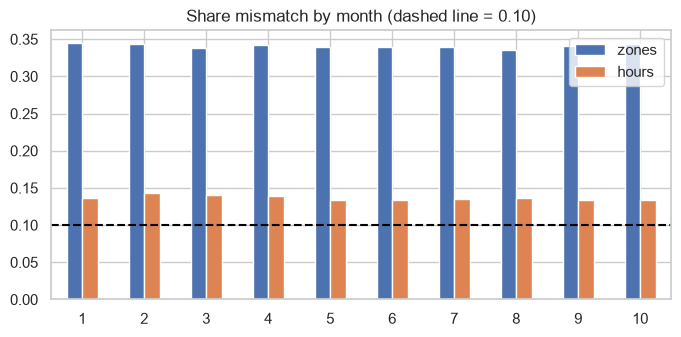

In [44]:
month_of_week = pd.Series(full_weeks.start_time.month, index=full_weeks)
by_month = pd.DataFrame(index=sorted(month_of_week.unique()))
by_month["zones"] = [share_mismatch(zone_by_week[month_of_week == m].mean()) for m in by_month.index]
by_month["hours"] = [share_mismatch(hour_by_week[month_of_week == m].mean()) for m in by_month.index]
by_month["weeks"] = [int((month_of_week == m).sum()) for m in by_month.index]
display(by_month)

by_month[["zones", "hours"]].plot.bar(figsize=(8, 3.5), rot=0)
plt.axhline(PRACTICAL_GAP, color="black", linestyle="--")
plt.title("Share mismatch by month (dashed line = 0.10)")
plt.show()

In [45]:
zone_gap = h1_table.loc["Pickup zone", "share mismatch"]
hour_gap = h1_table.loc["Hour of day", "share mismatch"]
both_significant = (h1_table["adjusted p"] < 0.05).all()
every_month_above = (by_month[["zones", "hours"]] > PRACTICAL_GAP).all().all()

if both_significant and zone_gap > PRACTICAL_GAP and hour_gap > PRACTICAL_GAP and every_month_above:
    h1_verdict = "supported"
elif zone_gap < PRACTICAL_GAP or hour_gap < PRACTICAL_GAP:
    h1_verdict = "not supported"
else:
    h1_verdict = "inconclusive"
print("H1 on January to October:", h1_verdict)

H1 on January to October: supported


In [46]:
show_finding(
    f"H1: {h1_verdict}",
    (f"Over {len(full_weeks)} complete weeks the share mismatch is {zone_gap:.2f} across zones "
     f"and {hour_gap:.2f} across hours. Kendall's W is "
     f"{h1_table.loc['Pickup zone', 'Kendall W']:.3f} and {h1_table.loc['Hour of day', 'Kendall W']:.3f}. "
     f"The lowest monthly mismatch is {by_month['zones'].min():.2f} (zones) and "
     f"{by_month['hours'].min():.2f} (hours)."),
    ("Busy zones and busy hours stay the same from week to week and in every month. "
     "Weeks are not fully independent and zone size is not controlled, so the p-values are only a guide."),
    ("Uneven demand is a reason to test informed placement against equal or random placement. "
     "It does not prove that informed placement earns more profit."))

**H1: supported**

- Observation: Over 42 complete weeks the share mismatch is 0.34 across zones and 0.14 across hours. Kendall's W is 0.996 and 0.977. The lowest monthly mismatch is 0.34 (zones) and 0.13 (hours).
- Inference: Busy zones and busy hours stay the same from week to week and in every month. Weeks are not fully independent and zone size is not controlled, so the p-values are only a guide.
- Decision relevance: Uneven demand is a reason to test informed placement against equal or random placement. It does not prove that informed placement earns more profit.

## 14. Is the forecast fair across zones?

We take the 4-week mean from Section 12 and compare its error for different kinds of zones. Zones are split into four equal-size groups by average demand (Low to High) and also grouped by borough.

The error is WAPE: total absolute error divided by total demand in the group. This is only a check on the data and on a simple baseline. Real service to riders is measured in the simulator.

In [47]:
error_by_zone = (four_week[usable] - actual).abs().sum()
demand_by_zone = actual.sum()

groups = pd.qcut(zone_average, 4, labels=["Low", "Lower-middle", "Upper-middle", "High"])
borough_of_zone = hours.drop_duplicates("zone_id").set_index("zone_id")["borough"]

fair = pd.DataFrame({"error": error_by_zone, "demand": demand_by_zone})
fair["group"] = groups
fair["borough"] = borough_of_zone

by_group = fair.groupby("group", observed=True)[["error", "demand"]].sum()
by_group["WAPE %"] = 100 * by_group["error"] / by_group["demand"]
by_borough = fair.groupby("borough")[["error", "demand"]].sum()
by_borough["WAPE %"] = 100 * by_borough["error"] / by_borough["demand"]
by_borough = by_borough[by_borough["demand"] > 0.01 * by_borough["demand"].sum()]
display(by_group[["WAPE %"]])
display(by_borough[["WAPE %"]])

,WAPE %
group,
Low,25.92
Lower-middle,15.42
Upper-middle,13.03
High,12.81


,WAPE %
borough,
Bronx,12.79
Brooklyn,13.78
Manhattan,13.50
Queens,14.13
Staten Island,19.56


In [48]:
low_wape = by_group.loc["Low", "WAPE %"]
high_wape = by_group.loc["High", "WAPE %"]

show_finding(
    "Fairness: quiet zones are predicted worse",
    (f"The 4-week mean has a WAPE of {low_wape:.0f}% in the quietest quarter of zones and "
     f"{high_wape:.0f}% in the busiest quarter."),
    ("Small counts are mostly luck, so a quiet zone is hard to forecast in relative terms. "
     "A plan that follows the forecast will serve quiet zones less well."),
    ("Add a minimum service level for every zone in the simulator and report served share "
     "for low-demand and high-demand zones separately."))

**Fairness: quiet zones are predicted worse**

- Observation: The 4-week mean has a WAPE of 26% in the quietest quarter of zones and 13% in the busiest quarter.
- Inference: Small counts are mostly luck, so a quiet zone is hard to forecast in relative terms. A plan that follows the forecast will serve quiet zones less well.
- Decision relevance: Add a minimum service level for every zone in the simulator and report served share for low-demand and high-demand zones separately.

## 15. Quick check: random placement against placing by the forecast

This is a small proxy, not the full simulation. Use only the Manhattan zones. In every hour:

- demand is 1% of the real requests of each zone (the same thinning as the simulator)
- each of the N cars picks a zone at random, with a seed
- **random plan**: every zone has the same chance
- **our plan**: a zone's chance is its share of the 4-week-mean forecast
- a request is served if there is a car in its own zone. Travel and cost are ignored.

We compare the share of requests served each day, with a paired Wilcoxon test over the same days. The full profit simulation is in Phase 4 to 6.

In [49]:
manhattan = borough_of_zone[borough_of_zone == "Manhattan"].index
real_demand = (wide[usable][manhattan] * DEMAND_SCALE).to_numpy()
forecast = four_week[usable][manhattan].to_numpy()
days = wide[usable].index.normalize()

zone_count = len(manhattan)
random_chance = np.full(zone_count, 1 / zone_count)
rng = np.random.default_rng(SEED)
print(zone_count, "Manhattan zones,", len(real_demand), "hours")

69 Manhattan zones, 5135 hours


In [50]:
results = []
for hour in range(len(real_demand)):
    demand_now = real_demand[hour]
    our_chance = forecast[hour] / forecast[hour].sum()
    for fleet in FLEET_SIZES:
        random_cars = rng.multinomial(fleet, random_chance)
        our_cars = rng.multinomial(fleet, our_chance)
        results.append({
            "day": days[hour], "fleet": fleet, "demand": demand_now.sum(),
            "random served": np.minimum(random_cars, demand_now).sum(),
            "our served": np.minimum(our_cars, demand_now).sum()})

per_day = pd.DataFrame(results).groupby(["fleet", "day"]).sum()
per_day["random share"] = per_day["random served"] / per_day["demand"]
per_day["our share"] = per_day["our served"] / per_day["demand"]
print(len(per_day), "fleet-days")

642 fleet-days


In [51]:
comparison_rows = []
for fleet in FLEET_SIZES:
    day_table = per_day.loc[fleet]
    random_mean = day_table["random share"].mean()
    our_mean = day_table["our share"].mean()
    p_value = stats.wilcoxon(day_table["our share"], day_table["random share"],
                             alternative="greater").pvalue
    comparison_rows.append({
        "cars": fleet, "days": len(day_table),
        "random served %": 100 * random_mean, "ours served %": 100 * our_mean,
        "gain %": 100 * (our_mean / random_mean - 1),
        "days ours is better %": 100 * (day_table["our share"] > day_table["random share"]).mean(),
        "Wilcoxon p": p_value})

comparison = pd.DataFrame(comparison_rows).set_index("cars")
display(comparison.assign(**{"Wilcoxon p": comparison["Wilcoxon p"].map("{:.1e}".format)}))

,days,random served %,ours served %,gain %,days ours is better %,Wilcoxon p
cars,,,,,,
25,214,17.02,20.82,22.36,100.00,3.6e-37
50,214,31.34,38.39,22.50,100.00,3.6e-37
100,214,53.54,64.09,19.72,100.00,3.6e-37


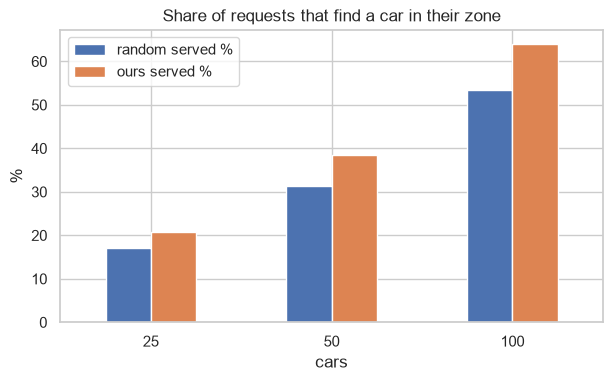

In [52]:
comparison[["random served %", "ours served %"]].plot.bar(figsize=(7, 3.8), rot=0)
plt.title("Share of requests that find a car in their zone")
plt.ylabel("%")
plt.show()

In [53]:
gains = comparison["gain %"]
better_days = comparison["days ours is better %"].min()
if better_days == 100:
    better_text = "every day"
else:
    better_text = f"at least {better_days:.0f}% of the days"

show_finding(
    "Random against our placement: placing by forecast serves more requests",
    (f"Placing cars by the 4-week-mean forecast serves {gains[25]:.0f}%, {gains[50]:.0f}% and "
     f"{gains[100]:.0f}% more requests than random placement with 25, 50 and 100 cars. "
     f"Ours is better on {better_text}."),
    ("Where cars wait matters. The gain is about 20 to 22% for every fleet size and a little "
     "smaller with 100 cars, where a big fleet covers many zones even by luck. This ignores "
     "travel, cost and cars that are busy, so it is not a profit result."),
    ("Supports the idea behind D2 (place cars by expected demand). The profit simulation "
     "must confirm it with empty miles and idle time included."))

**Random against our placement: placing by forecast serves more requests**

- Observation: Placing cars by the 4-week-mean forecast serves 22%, 22% and 20% more requests than random placement with 25, 50 and 100 cars. Ours is better on every day.
- Inference: Where cars wait matters. The gain is about 20 to 22% for every fleet size and a little smaller with 100 cars, where a big fleet covers many zones even by luck. This ignores travel, cost and cars that are busy, so it is not a profit result.
- Decision relevance: Supports the idea behind D2 (place cars by expected demand). The profit simulation must confirm it with empty miles and idle time included.

## 16. What the EDA tells us

All findings in one table: observation, inference, and decision relevance.

In [54]:
pd.set_option("display.max_colwidth", None)
findings_table = pd.DataFrame(FINDINGS)
findings_table.index = findings_table.index + 1
display(findings_table)

,Topic,Observation,Inference,Decision relevance
1,"Data quality: little is lost, but not evenly",98.99% of the trip records pass cleaning. The rule 'request not before pickup' removes 1.69% of Lyft trips and 0.68% of Uber trips. 0 zone-hours have no request count.,"The demand count is almost complete, but it is a count of eligible completed trips, not of all requests. Lyft loses more trips than Uber, so the count may lean slightly towards Uber. We cannot tell how large that bias is.","Call the demand 'eligible completed trips' everywhere and keep missing hours missing, never zero. Mention this limit when we present the launch area (D1)."
2,Shape of demand: lopsided and noisy,"The mean is 102.1 requests per zone-hour but the median is 67 and the maximum is 1,691 (skew 2.8). Variance is about 2.1 times the mean. In the quietest quarter of zones, 17% of zone-hours have no request.","A few very busy zone-hours pull the mean up, and the counts swing more than pure chance. Part of that is real change (weather, events) and part is luck in small counts.","Keep a Poisson-type loss as a candidate for the forecast, and report forecast error as WAPE (total error divided by total demand) so empty hours do not break it. Do not promise exact counts for the quietest zones (D2)."
3,Outliers: unusual days are mostly explained,9 of 305 days are flagged. 7 of them are federal holidays or have rainy hours. No count is negative.,"These days are real swings in demand, not data errors. The few without a holiday or rain probably come from events or transit problems, which we do not have in the data.","Keep these days in training, because they are exactly where a forecast is hardest. Report holidays and wet days separately when we evaluate plans."
4,"Demand over time: strong weekly rhythm, small month effect","The busiest slot is Sat at 22:00 with 47,683 requests per hour for the city. At 04:00 demand is only 20% of that. The lowest and highest month are 11 index points apart.",Weekday and hour explain most of the pattern. The shape repeats every week.,"Plan car positions by weekday and hour, not by month. The evening and weekend-night peaks are where a small fleet is most likely to run short (D2)."
5,"Demand by zone: spread out, but with a clear core","57 zones hold half of the demand, 123 hold 80% and 161 hold 90% of 263. The ten busiest zones hold 13%. Manhattan holds 39% of demand.","Demand is not concentrated in a handful of zones, so a launch area has to be fairly large to cover most requests. Outer-borough demand is real but thin.","Choose the launch area (D1) by comparing profit, not only by demand share, because thin zones are expensive to serve with few cars."
6,Trip economics: a trip leaves a modest margin,The average trip is 5.0 miles and 20 minutes with a base fare of 25.81 USD. After 1.36 USD per mile 18.97 USD is left.,"Trips differ by borough. Every empty mile costs the same as a paid mile but earns nothing, so a few empty miles remove a large part of this margin.","The wait-or-move rule (D3) has to count the empty-mile cost of every move, otherwise moving cars always looks good."
7,Flows: cars drift towards a few zones,East Village loses the most cars (+62.9 net pickups per hour). Newark Airport collects the most (-172.5).,Airports and end-of-line zones collect cars that must drive back empty. Zones that lose cars every hour need cars sent in.,"Test 'stay' against 'drive empty to a busier zone' with the empty-mile cost included (D3), and look first at the zones that lose or collect the most cars."
8,"Rain: demand goes up, and three stations agree","In rainy hours demand is 10.3% above matched dry hours (95% interval 7.7% to 12.8%, 516 wet hours). LaGuardia shows 9.0% and JFK 9.0%.","People take a car more when it rains. All three stations point the same way, so this is not a quirk of one weather station. It is an association, not a proven cause.","Rain is a candidate input for the forecast (planned notebook 03d). The gain is about a te

### How this notebook fits the BADIR steps

| BADIR step | Where in this notebook |
|---|---|
| Business question | Sections 1, 8, 9, 10, 15: every finding names the decision it affects (D1, D2, D3) |
| Analysis plan | Section 1 settings table and the H1 rule in Section 13, both written before the results |
| Data collection | Sections 2 to 4: data card, missing values, cleaning rules, provider check |
| Insights | Sections 5 to 15 |
| Recommendations | Section 16 table, which feeds the report and the next notebooks |

In [55]:
assert hours["event_date_nyc"].max() <= pd.Timestamp(LAST_DAY_ALLOWED)
assert len(findings_table) >= 10

audit = {
    "rows_used": len(hours),
    "last_date": str(hours["event_date_nyc"].max().date()),
    "complete_weeks": len(full_weeks),
    "h1_verdict": h1_verdict,
    "share_mismatch_zones": float(zone_gap),
    "share_mismatch_hours": float(hour_gap),
    "rain_change_percent": float(rain_change),
    "baseline_mae": {name: float(value) for name, value in baseline_scores["MAE"].items()},
    "gain_over_random_percent": {int(size): float(value) for size, value in gains.items()},
    "findings": len(findings_table)}

findings_table.to_csv(OUTPUT / "findings.csv", index_label="number")
(OUTPUT / "audit.json").write_text(json.dumps(audit, indent=2), encoding="utf-8")
print("Saved findings and audit to", OUTPUT.relative_to(ROOT))

Saved findings and audit to data\eda\phase2_simple
